<a href="https://colab.research.google.com/github/oninonins/Machine-learning-/blob/main/JS06%20-%20ANN/Praktikum_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 3 — Exact NN vs HNSW (hnswlib)

HNSW (*Hierarchical Navigable Small World*) adalah index graph berlapis: pencarian dimulai dari node paling atas, turun ke bawah sambil menyimpan daftar kandidat terbaik. Karena itu HNSW tidak perlu memindai seluruh data seperti brute force.

- **ENN (exact)** = `sklearn.NearestNeighbors` dengan `algorithm='brute'`.
- **HNSW** = `hnswlib`, parameter `M` (jumlah tetangga per node), `ef_construction` (ketelitian saat build), dan `ef` (ketelitian saat query).
- `hnswlib` hanya mendukung tiga space: **`l2`** (Euclidean), **`ip`** (inner product), **`cosine`** (angular). Tidak ada Manhattan di hnswlib.
- **Penting:** untuk space `l2`, `hnswlib.knn_query` mengembalikan **squared L2** (jarak kuadrat), sedangkan `sklearn` mengembalikan Euclidean. Agar perbandingan adil, jarak HNSW di-`sqrt` terlebih dahulu.

Tahap 1 mengikuti modul (1000 data 2D). Tahap 2 melakukan percobaan metrik distance berbeda, 1.000 vs 1.000.000 data, dan 2D vs 5D data, lalu hasilnya dicatat pada tabel seperti di Praktikum 1.

In [7]:
!pip install hnswlib

=== Exact NN ===
Indices: [[137 170 750 316 991]]
Distances (Euclidean): [[0.01144331 0.0278216  0.02824018 0.03417073 0.04514859]]
Waktu: 0.001735687255859375 detik

=== HNSW ===
Indices: [[137 170 750 316 991]]
Distances (Euclidean): [[0.01144331 0.0278216  0.02824018 0.03417073 0.04514859]]
Waktu: 0.00028324127197265625 detik


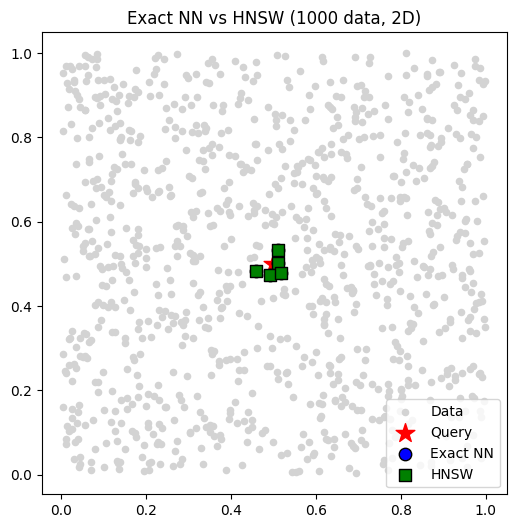

In [8]:
import numpy as np
import time
import hnswlib
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# ===========================
# 1. Buat data 2D acak
# ===========================
num_elements = 1000
dim = 2
np.random.seed(42)
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances (Euclidean):", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
# Inisialisasi index HNSW
p = hnswlib.Index(space='l2', dim=dim)   # opsi: l2, ip, cosine

# Ukuran maksimum elemen yang bisa ditampung
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Tambahkan data
p.add_items(data)

# Set parameter pencarian
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances_hnsw = p.knn_query(query, k=k)
end = time.time()

# hnswlib l2 mengembalikan squared L2, ubah ke Euclidean
distances_hnsw = np.sqrt(distances_hnsw)

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances (Euclidean):", distances_hnsw)
print("Waktu:", end - start, "detik")

# ===========================
# 4. Visualisasi hasil
# ===========================
plt.figure(figsize=(6, 6))
plt.scatter(data[:, 0], data[:, 1], c="lightgray", s=20, label="Data")
plt.scatter(query[0, 0], query[0, 1], c="red", marker="*", s=200, label="Query")

plt.scatter(data[indices[0], 0], data[indices[0], 1], c="blue", s=80, edgecolor="k", label="Exact NN")
plt.scatter(data[labels[0], 0], data[labels[0], 1], c="green", s=80, marker="s", edgecolor="k", label="HNSW")

plt.legend()
plt.title("Exact NN vs HNSW (1000 data, 2D)")
plt.show()

In [9]:
# -------------------------------
# Percobaan: metrik distance x jumlah data x dimensi
# -------------------------------
import gc
import pandas as pd

DIMS   = [2, 5]
SIZES  = [1_000, 1_000_000]
SPACES = ["l2", "ip", "cosine"]      # hanya space yang didukung hnswlib

K_SWEEP      = 5
N_QUERY      = 20
M            = 16
EF_CONSTRUCTION = 100
EF_SEARCH    = 50
SEED         = 42

METRIC_LABEL = {"l2": "Euclidean (l2)",
                "ip": "Inner Product (ip)",
                "cosine": "Cosine (Angular)"}


def enn_topk(X, q, space, k=K_SWEEP):
    """Exact nearest neighbour brute force, dihitung dengan cara yang sama dengan hnswlib:
       l2 -> sum((x-q)^2), ip -> -(x.q), cosine -> 1 - cos(x,q)."""
    if space == "l2":
        d = np.sum((X - q) ** 2, axis=1)
    elif space == "ip":
        d = -(X @ q)
    else:
        d = 1.0 - (X @ q) / (np.maximum(np.linalg.norm(X, axis=1), 1e-12) * np.linalg.norm(q))
    idx = np.argpartition(d, k)[:k]
    return idx[np.argsort(d[idx])]


rows = []
for dim in DIMS:
    for n in SIZES:
        rng = np.random.default_rng(SEED)
        X = rng.random((n, dim), dtype=np.float32)
        Q = rng.random((N_QUERY, dim), dtype=np.float32)

        for space in SPACES:
            # --- ENN (brute force) ---
            t0 = time.perf_counter()
            enn_idx = [enn_topk(X, q, space) for q in Q]
            t_enn = (time.perf_counter() - t0) / len(Q) * 1000        # ms per query

            # --- HNSW ---
            p = hnswlib.Index(space=space, dim=dim)
            t0 = time.perf_counter()
            p.init_index(max_elements=n, ef_construction=EF_CONSTRUCTION, M=M)
            p.add_items(X)
            t_build = time.perf_counter() - t0
            p.set_ef(EF_SEARCH)

            t0 = time.perf_counter()
            ann_idx, _ = p.knn_query(Q, k=K_SWEEP)
            t_query = (time.perf_counter() - t0) / len(Q) * 1000      # ms per query

            recall = float(np.mean([len(set(a) & set(b)) / K_SWEEP
                                    for a, b in zip(enn_idx, ann_idx)]))

            rows.append({
                "Distance Metrics": METRIC_LABEL[space],
                "Tree": f"M={M}, ef={EF_SEARCH}, ef_construction={EF_CONSTRUCTION}",
                "Jumlah data": n,
                "D (dimensi)": dim,
                "ENN top-5": list(map(int, enn_idx[0])),
                "HNSW top-5": list(map(int, ann_idx[0])),
                "Recall@5": round(recall, 3),
                "Waktu build (s)": round(t_build, 3),
                "Waktu query ENN (ms)": round(t_enn, 3),
                "Waktu query HNSW (ms)": round(t_query, 3),
            })
            print(f"{METRIC_LABEL[space]:22s} | d={dim} | N={n:,} | recall@5={recall:.3f} "
                  f"| build {t_build:.2f} s | ENN {t_enn:.3f} ms | HNSW {t_query:.3f} ms")

            del p
            gc.collect()

hasil = pd.DataFrame(rows)
display(hasil)

Euclidean (l2)         | d=2 | N=1,000 | recall@5=1.000 | build 0.05 s | ENN 0.100 ms | HNSW 0.060 ms
Inner Product (ip)     | d=2 | N=1,000 | recall@5=0.980 | build 0.05 s | ENN 0.048 ms | HNSW 0.037 ms
Cosine (Angular)       | d=2 | N=1,000 | recall@5=1.000 | build 0.04 s | ENN 0.116 ms | HNSW 0.051 ms
Euclidean (l2)         | d=2 | N=1,000,000 | recall@5=1.000 | build 110.34 s | ENN 87.089 ms | HNSW 0.142 ms
Inner Product (ip)     | d=2 | N=1,000,000 | recall@5=0.950 | build 61.99 s | ENN 26.571 ms | HNSW 0.021 ms
Cosine (Angular)       | d=2 | N=1,000,000 | recall@5=0.070 | build 85.04 s | ENN 42.704 ms | HNSW 0.075 ms
Euclidean (l2)         | d=5 | N=1,000 | recall@5=1.000 | build 0.08 s | ENN 0.088 ms | HNSW 0.102 ms
Inner Product (ip)     | d=5 | N=1,000 | recall@5=0.970 | build 0.07 s | ENN 0.043 ms | HNSW 0.033 ms
Cosine (Angular)       | d=5 | N=1,000 | recall@5=1.000 | build 0.06 s | ENN 0.114 ms | HNSW 0.031 ms
Euclidean (l2)         | d=5 | N=1,000,000 | recall@5=1.000 | b

,Distance Metrics,Tree,Jumlah data,D (dimensi),ENN top-5,HNSW top-5,Recall@5,Waktu build (s),Waktu query ENN (ms),Waktu query HNSW (ms)
0,Euclidean (l2),"M=16, ef=50, ef_construction=100",1000,2,"[258, 17, 971, 187, 794]","[258, 17, 971, 187, 794]",1.00,0.047,0.100,0.060
1,Inner Product (ip),"M=16, ef=50, ef_construction=100",1000,2,"[584, 173, 779, 72, 200]","[584, 173, 779, 72, 345]",0.98,0.050,0.048,0.037
2,Cosine (Angular),"M=16, ef=50, ef_construction=100",1000,2,"[74, 820, 17, 84, 512]","[74, 820, 17, 84, 512]",1.00,0.045,0.116,0.051
3,Euclidean (l2),"M=16, ef=50, ef_construction=100",1000000,2,"[600900, 695075, 587490, 751043, 109689]","[600900, 695075, 587490, 751043, 109689]",1.00,110.342,87.089,0.142
4,Inner Product (ip),"M=16, ef=50, ef_construction=100",1000000,2,"[774544, 430626, 318370, 878003, 875994]","[774544, 430626, 318370, 878003, 875994]",0.95,61.989,26.571,0.021
5,Cosine (Angular),"M=16, ef=50, ef_construction=100",1000000,2,"[626177, 412578, 163286, 719539, 18613]","[85886, 593858, 681528, 780895, 797002]",0.07,85.045,42.704,0.075
6,Euclidean (l2),"M=16, ef=50, ef_construction=100",1000,5,"[812, 34, 550, 962, 251]","[812, 34, 550, 962, 251]",1.00,0.078,0.088,0.102
7,Inner Product (ip),"M=16, ef=50, ef_construction=100",1000,5,"[749, 817, 477, 433, 575]","[749, 817, 477, 433, 575]",0.97,0.067,0.043,0.033
8,Cosine (Angular),"M=16, ef=50, ef_construction=100",1000,5,"[812, 730, 64, 460, 34]","[812, 730, 64, 460, 34]",1.00,0.058,0.114,0.031
9,Euclidean (l2),"M=16, ef=50, ef_construction=100",1000000,5,"[85158, 586716, 687018, 8630, 91763]","[85158, 586716, 687018, 8630, 91763]",1.00,85.318,62.580,0.044


In [10]:
# Tabel laporan (format Praktikum 1)
tabel = pd.DataFrame({
    "Distance Metrics": hasil["Distance Metrics"],
    "Tree": hasil["Tree"],
    "Jumlah data": hasil["Jumlah data"],
    "Hasil Index terdekat ENN vs ANN": [
        f"ENN: {e} vs HNSW: {a} (recall@5={r})"
        for e, a, r in zip(hasil["ENN top-5"], hasil["HNSW top-5"], hasil["Recall@5"])],
    "Waktu komputasi": [
        f"build {b} s; query ENN {e} ms vs HNSW {h} ms"
        for b, e, h in zip(hasil["Waktu build (s)"], hasil["Waktu query ENN (ms)"], hasil["Waktu query HNSW (ms)"])],
})

display(hasil)                       # detail semua kolom
try:
    display(tabel.style.hide(axis='index'))   # butuh paket jinja2
except Exception:
    display(tabel)
try:
    print(tabel.to_markdown(index=False))     # butuh paket tabulate
except ImportError:
    print(tabel.to_string(index=False))       # fallback kalau tabulate belum ada

,Distance Metrics,Tree,Jumlah data,D (dimensi),ENN top-5,HNSW top-5,Recall@5,Waktu build (s),Waktu query ENN (ms),Waktu query HNSW (ms)
0,Euclidean (l2),"M=16, ef=50, ef_construction=100",1000,2,"[258, 17, 971, 187, 794]","[258, 17, 971, 187, 794]",1.00,0.047,0.100,0.060
1,Inner Product (ip),"M=16, ef=50, ef_construction=100",1000,2,"[584, 173, 779, 72, 200]","[584, 173, 779, 72, 345]",0.98,0.050,0.048,0.037
2,Cosine (Angular),"M=16, ef=50, ef_construction=100",1000,2,"[74, 820, 17, 84, 512]","[74, 820, 17, 84, 512]",1.00,0.045,0.116,0.051
3,Euclidean (l2),"M=16, ef=50, ef_construction=100",1000000,2,"[600900, 695075, 587490, 751043, 109689]","[600900, 695075, 587490, 751043, 109689]",1.00,110.342,87.089,0.142
4,Inner Product (ip),"M=16, ef=50, ef_construction=100",1000000,2,"[774544, 430626, 318370, 878003, 875994]","[774544, 430626, 318370, 878003, 875994]",0.95,61.989,26.571,0.021
5,Cosine (Angular),"M=16, ef=50, ef_construction=100",1000000,2,"[626177, 412578, 163286, 719539, 18613]","[85886, 593858, 681528, 780895, 797002]",0.07,85.045,42.704,0.075
6,Euclidean (l2),"M=16, ef=50, ef_construction=100",1000,5,"[812, 34, 550, 962, 251]","[812, 34, 550, 962, 251]",1.00,0.078,0.088,0.102
7,Inner Product (ip),"M=16, ef=50, ef_construction=100",1000,5,"[749, 817, 477, 433, 575]","[749, 817, 477, 433, 575]",0.97,0.067,0.043,0.033
8,Cosine (Angular),"M=16, ef=50, ef_construction=100",1000,5,"[812, 730, 64, 460, 34]","[812, 730, 64, 460, 34]",1.00,0.058,0.114,0.031
9,Euclidean (l2),"M=16, ef=50, ef_construction=100",1000000,5,"[85158, 586716, 687018, 8630, 91763]","[85158, 586716, 687018, 8630, 91763]",1.00,85.318,62.580,0.044


Distance Metrics,Tree,Jumlah data,Hasil Index terdekat ENN vs ANN,Waktu komputasi
Euclidean (l2),"M=16, ef=50, ef_construction=100",1000,"ENN: [258, 17, 971, 187, 794] vs HNSW: [258, 17, 971, 187, 794] (recall@5=1.0)",build 0.047 s; query ENN 0.1 ms vs HNSW 0.06 ms
Inner Product (ip),"M=16, ef=50, ef_construction=100",1000,"ENN: [584, 173, 779, 72, 200] vs HNSW: [584, 173, 779, 72, 345] (recall@5=0.98)",build 0.05 s; query ENN 0.048 ms vs HNSW 0.037 ms
Cosine (Angular),"M=16, ef=50, ef_construction=100",1000,"ENN: [74, 820, 17, 84, 512] vs HNSW: [74, 820, 17, 84, 512] (recall@5=1.0)",build 0.045 s; query ENN 0.116 ms vs HNSW 0.051 ms
Euclidean (l2),"M=16, ef=50, ef_construction=100",1000000,"ENN: [600900, 695075, 587490, 751043, 109689] vs HNSW: [600900, 695075, 587490, 751043, 109689] (recall@5=1.0)",build 110.342 s; query ENN 87.089 ms vs HNSW 0.142 ms
Inner Product (ip),"M=16, ef=50, ef_construction=100",1000000,"ENN: [774544, 430626, 318370, 878003, 875994] vs HNSW: [774544, 430626, 318370, 878003, 875994] (recall@5=0.95)",build 61.989 s; query ENN 26.571 ms vs HNSW 0.021 ms
Cosine (Angular),"M=16, ef=50, ef_construction=100",1000000,"ENN: [626177, 412578, 163286, 719539, 18613] vs HNSW: [85886, 593858, 681528, 780895, 797002] (recall@5=0.07)",build 85.045 s; query ENN 42.704 ms vs HNSW 0.075 ms
Euclidean (l2),"M=16, ef=50, ef_construction=100",1000,"ENN: [812, 34, 550, 962, 251] vs HNSW: [812, 34, 550, 962, 251] (recall@5=1.0)",build 0.078 s; query ENN 0.088 ms vs HNSW 0.102 ms
Inner Product (ip),"M=16, ef=50, ef_construction=100",1000,"ENN: [749, 817, 477, 433, 575] vs HNSW: [749, 817, 477, 433, 575] (recall@5=0.97)",build 0.067 s; query ENN 0.043 ms vs HNSW 0.033 ms
Cosine (Angular),"M=16, ef=50, ef_construction=100",1000,"ENN: [812, 730, 64, 460, 34] vs HNSW: [812, 730, 64, 460, 34] (recall@5=1.0)",build 0.058 s; query ENN 0.114 ms vs HNSW 0.031 ms
Euclidean (l2),"M=16, ef=50, ef_construction=100",1000000,"ENN: [85158, 586716, 687018, 8630, 91763] vs HNSW: [85158, 586716, 687018, 8630, 91763] (recall@5=1.0)",build 85.318 s; query ENN 62.58 ms vs HNSW 0.044 ms


| Distance Metrics   | Tree                             |   Jumlah data | Hasil Index terdekat ENN vs ANN                                                                                 | Waktu komputasi                                       |
|:-------------------|:---------------------------------|--------------:|:----------------------------------------------------------------------------------------------------------------|:------------------------------------------------------|
| Euclidean (l2)     | M=16, ef=50, ef_construction=100 |          1000 | ENN: [258, 17, 971, 187, 794] vs HNSW: [258, 17, 971, 187, 794] (recall@5=1.0)                                  | build 0.047 s; query ENN 0.1 ms vs HNSW 0.06 ms       |
| Inner Product (ip) | M=16, ef=50, ef_construction=100 |          1000 | ENN: [584, 173, 779, 72, 200] vs HNSW: [584, 173, 779, 72, 345] (recall@5=0.98)                                 | build 0.05 s; query ENN 0.048 ms vs HNSW 0.037 ms     |
| Cosine (Angular)   | M

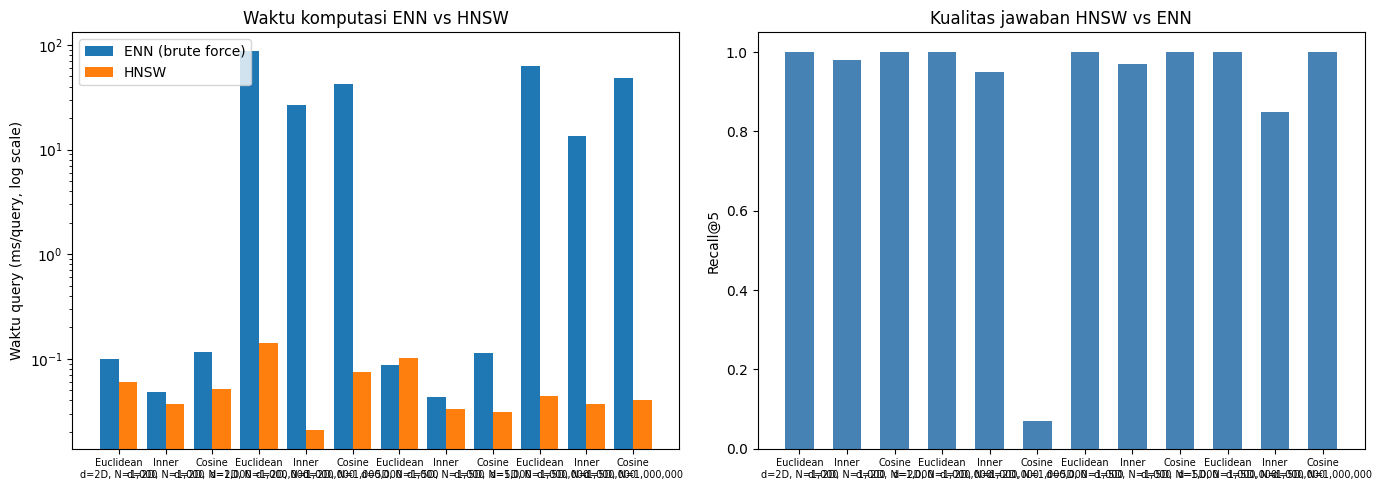

In [11]:
labels = [f"{r['Distance Metrics'].split()[0]}\nd={r['D (dimensi)']}D, N={r['Jumlah data']:,}" for _, r in hasil.iterrows()]
x = np.arange(len(hasil))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].bar(x - 0.2, hasil["Waktu query ENN (ms)"], 0.4, label="ENN (brute force)")
ax[0].bar(x + 0.2, hasil["Waktu query HNSW (ms)"], 0.4, label="HNSW")
ax[0].set_yscale("log")
ax[0].set_xticks(x); ax[0].set_xticklabels(labels, fontsize=7)
ax[0].set_ylabel("Waktu query (ms/query, log scale)")
ax[0].set_title("Waktu komputasi ENN vs HNSW")
ax[0].legend()

ax[1].bar(x, hasil["Recall@5"], 0.6, color="steelblue")
ax[1].set_ylim(0, 1.05)
ax[1].set_xticks(x); ax[1].set_xticklabels(labels, fontsize=7)
ax[1].set_ylabel("Recall@5")
ax[1].set_title("Kualitas jawaban HNSW vs ENN")

plt.tight_layout(); plt.show()

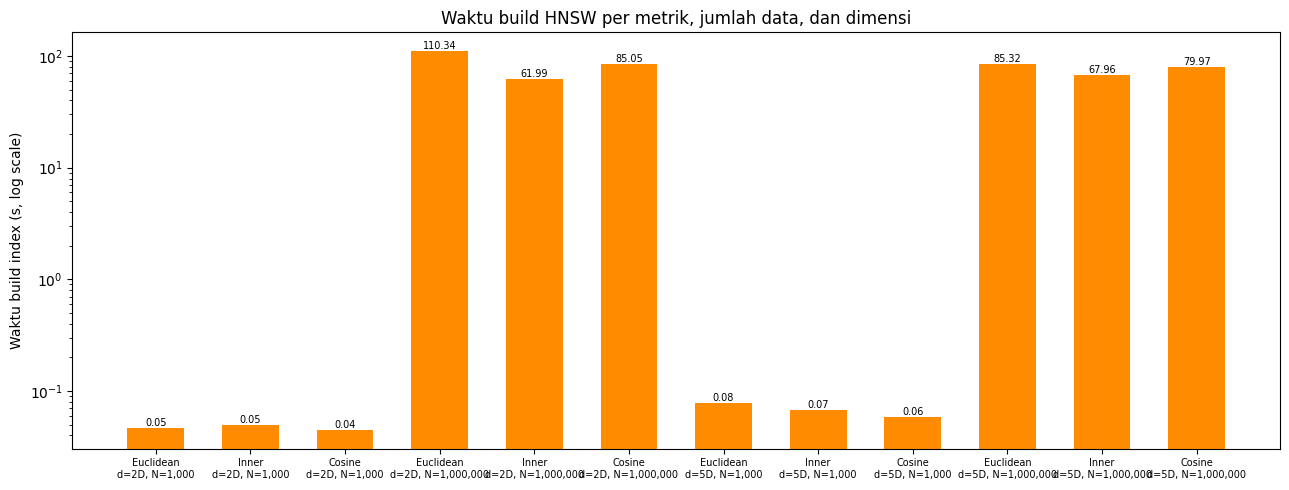

In [12]:
# Waktu build index (biaya sekali jalan saat preparasi) per konfigurasi
fig, ax = plt.subplots(figsize=(13, 5))
build = hasil["Waktu build (s)"].values
ax.bar(x, build, 0.6, color="darkorange")
ax.set_yscale("log")
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel("Waktu build index (s, log scale)")
ax.set_title("Waktu build HNSW per metrik, jumlah data, dan dimensi")
for xi, v in zip(x, build):
    ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
plt.tight_layout(); plt.show()

## Cara membaca hasil

- **Recall@5** = rata-rata porsi dari 5 tetangga ENN yang juga dikembalikan HNSW pada query yang sama. Nilai 1.0 berarti HNSW mengembalikan jawaban yang identik dengan brute force.
- **`M`** = jumlah maksimal tetangga per node di graph. Makin besar, graph makin padat: recall naik, memori dan waktu build ikut naik.
- **`ef_construction`** = ketelitian saat membangun graph (saat `add_items`). **`ef`** = ketelitian saat query, inilah tombol yang dipakai untuk trade-off recall vs kecepatan.
- **Satuan jarak `l2`:** `hnswlib` mengembalikan **squared L2**, sedangkan `sklearn` mengembalikan Euclidean. Pada demo, jarak HNSW sudah di-`sqrt` sehingga nilainya sebanding. Pada tabel benchmark, ENN dan HNSW sama-sama memakai squared L2 agar konsisten; yang dibandingkan adalah indeks dan recall, bukan nilai jaraknya.
- **Inner product (`ip`)** bukan metric sejati: titik bisa "lebih dekat" ke titik lain daripada ke dirinya sendiri. Pada percobaan ini recall `ip` berada di kisaran **0.85-0.98**, lebih rendah daripada `l2` pada data yang sama.
- **Cosine pada 2D, 1 juta data** menghasilkan recall sangat rendah (**0.07**). Ini bukan bug hnswlib: pada vektor acak non-negatif 2D, semua vektor berada di kuadran positif sehingga sudutnya mengumpul dan banyak kandidat memiliki cosine yang hampir sama (tie). Graph HNSW sulit membedakan tetangga yang jaraknya nyaris identik. Pada 5D, recall cosine kembali **1.0** karena pemisahan sudut lebih jelas. Menaikkan `ef` atau `M` juga dapat membantu, tetapi akar masalahnya adalah karakteristik data.
- **Waktu komputasi** dipecah dua: **build** (`init_index` + `add_items`, sekali jalan saat preparasi data) dan **query** (per permintaan pengguna). Pada data 1 juta baris, build jauh lebih berat daripada query.
- Di data acak berdimensi tinggi, tetangga terdekat nyaris tidak terdefinisi (jarak antar kandidat hampir sama), sehingga recall ANN bisa rendah meski algoritmanya benar. Ini efek data, bukan cacat HNSW.